# 10.3.2 Poço com gas lift

Poço vertical de 2048 m (5 in) em dois trechos: aresta 1 (líquido, 338 m, do reservatório a
170 bar com IPL = 0.98 kg/s/bar) e aresta 2 (mistura, 1710 m, padrão intermitente) até a
choke de produção (Cv = 30, 10 bar). O gás de elevação vem pela aresta 3 (linha de gás, 2 in,
1000 m, choke de gás Cv = 5) e desce pelo anular (aresta 4, 1710 m) até o vértice dinâmico 8,
que injeta no tubing por uma **válvula de retenção** (Cv = 5). Diferenças finitas centrais;
modelos monofásicos nas arestas 1, 3 e 4.

* Cenário 1 (sem intermitência): choke de gás 100 % → 75 % entre 100 e 150 s (Figuras 10.36–10.40).
* Cenário 2 (com intermitência): choke de gás 75 % → 15 % entre 100 e 150 s (Figuras 10.41–10.46).

Nota: o ficheiro do cenário 1 tem o vértice 8 gravado como estático; o caso exportado usa a rede
do cenário 2 com a tabela da choke do cenário 1 ([issue 001](../../docs/issues/001-reproducao-capitulo-10.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thesis.notebook_utils import thesis_run, compare_states, show_pipe, plot_elements, plot_vertices
from thesis.mf2 import legacy_pipe_dict
from mfsim.plotting import pipe_profiles, compare_runs
from mfsim.runs import load_run

names = ["poço (líquido)", "tubing (bifásico)", "linha de gás", "anular"]

## Cenário 2 - com intermitência (comparação direta com o MATLAB)

10.3.2 Poço com gas lift - cenário 2 (com intermitência)
Choke de gás 75%->15% entre 100 e 150 s.
Figuras da tese: Figs. 10.41-10.46
corrida 10_3_2b.npz: integrador bdf (rtol 0.0001, atol 0.01, max_step 5.0), 601 instantes de saída até 3000 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 liquid       PT        5.16e-04       4.16e-01   1.24e-03
   1 liquid       qL        4.88e-02       1.48e+01   3.29e-03
   2 beggs_brill  PT        8.69e-04       1.25e+00   6.96e-04
   2 beggs_brill  qL        1.46e-01       1.46e+01   1.00e-02
   2 beggs_brill  qG        9.89e-03       8.04e-01   1.23e-02
   3 gas          PT        7.00e-04       6.91e-02   1.01e-02
   3 gas          qG        1.38e-02       6.50e-01   2.13e-02
   4 gas          PT        4.35e-04       2.92e-01   1.49e-03
   4 gas          qG        1.16e-02       7.93e-01   1.46e-02
vértices dinâmicos: máx |dif| = [3.14193116e-13 4.39230639e-04]


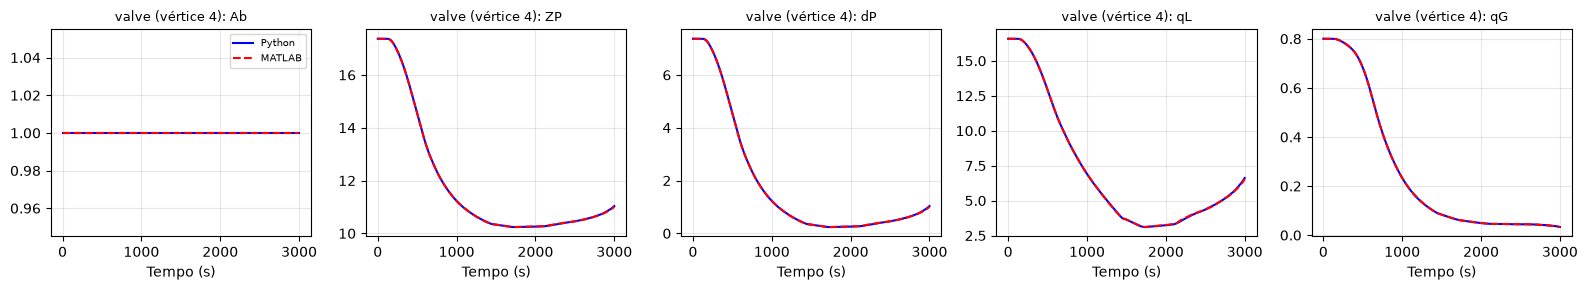

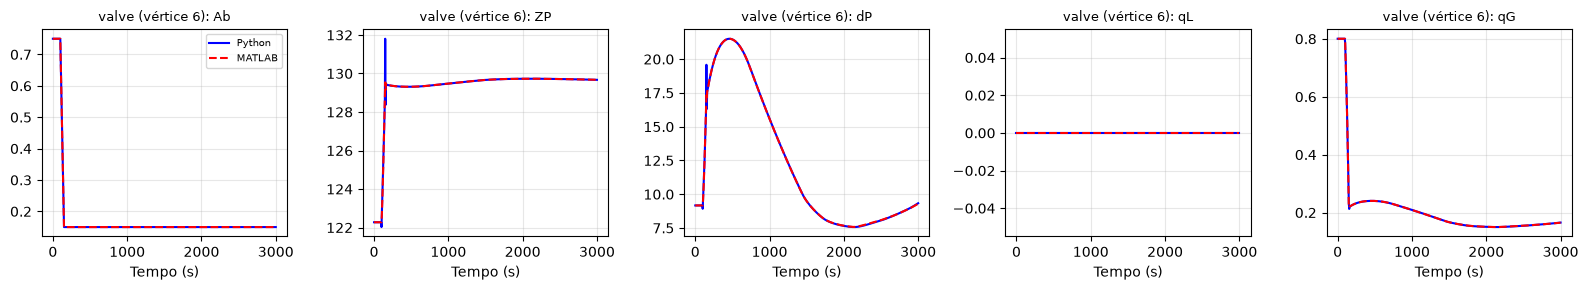

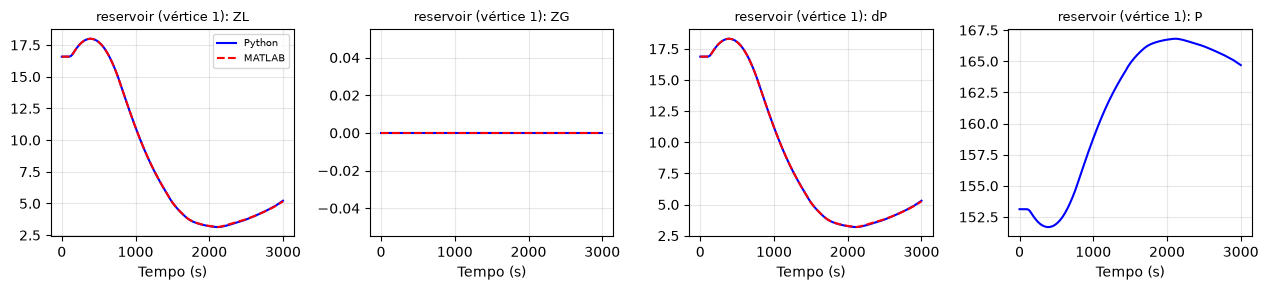

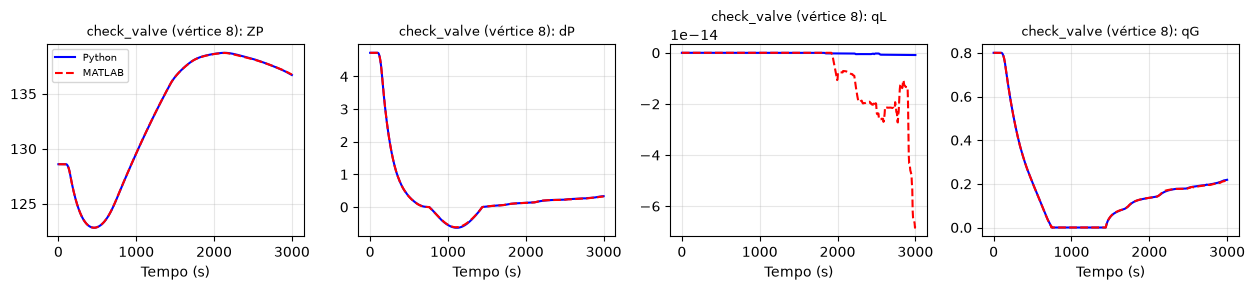

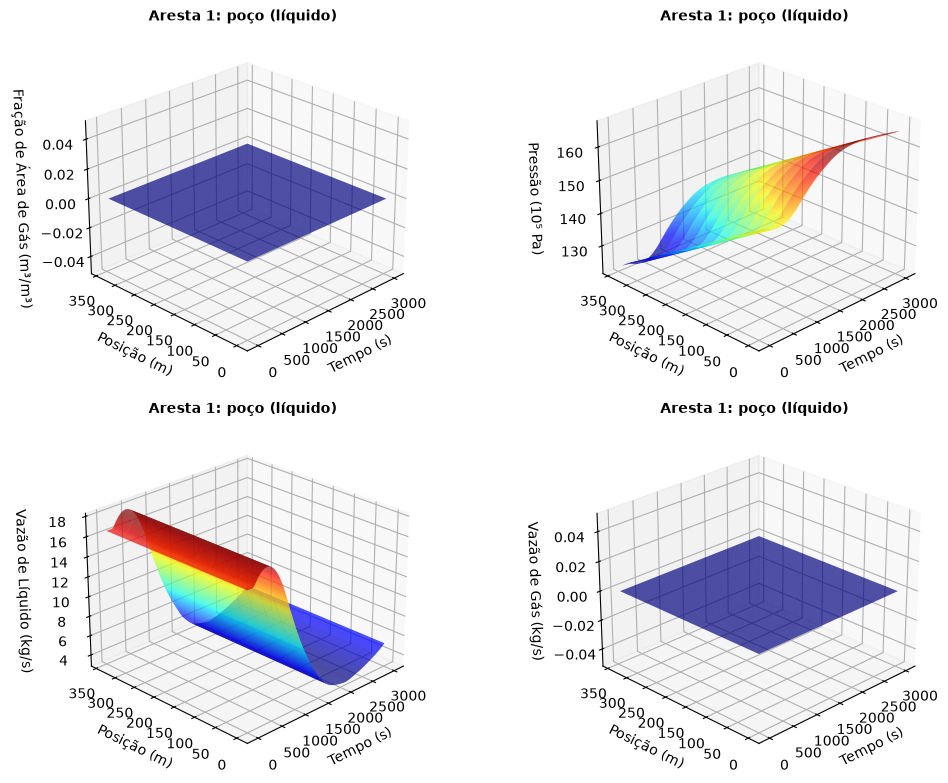

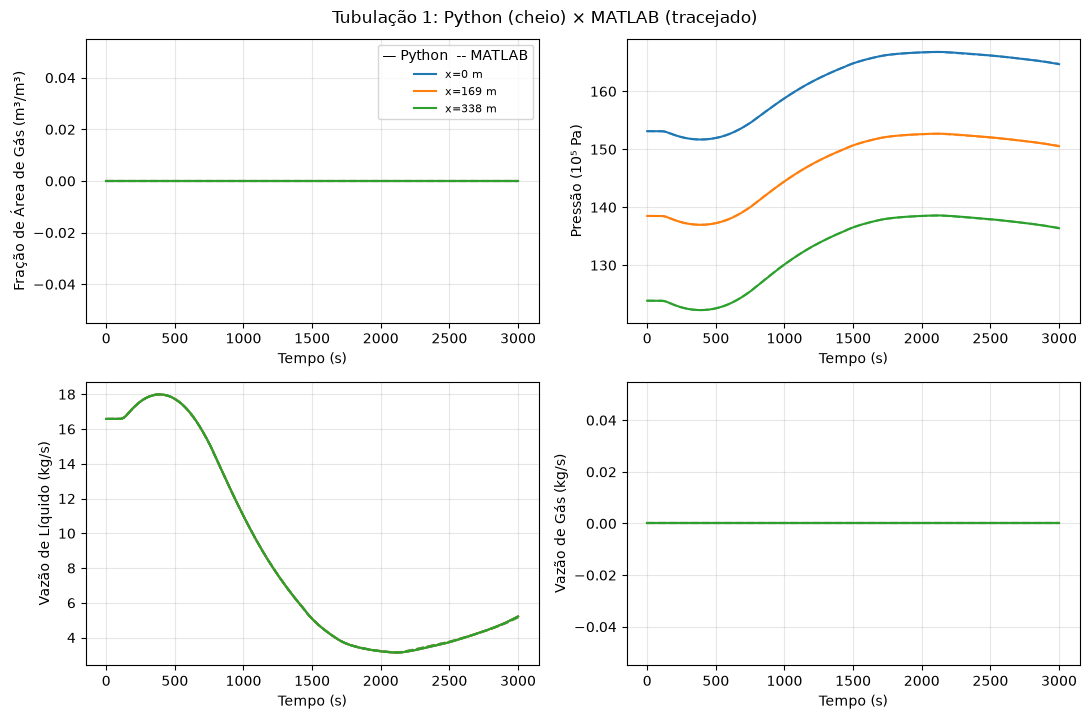

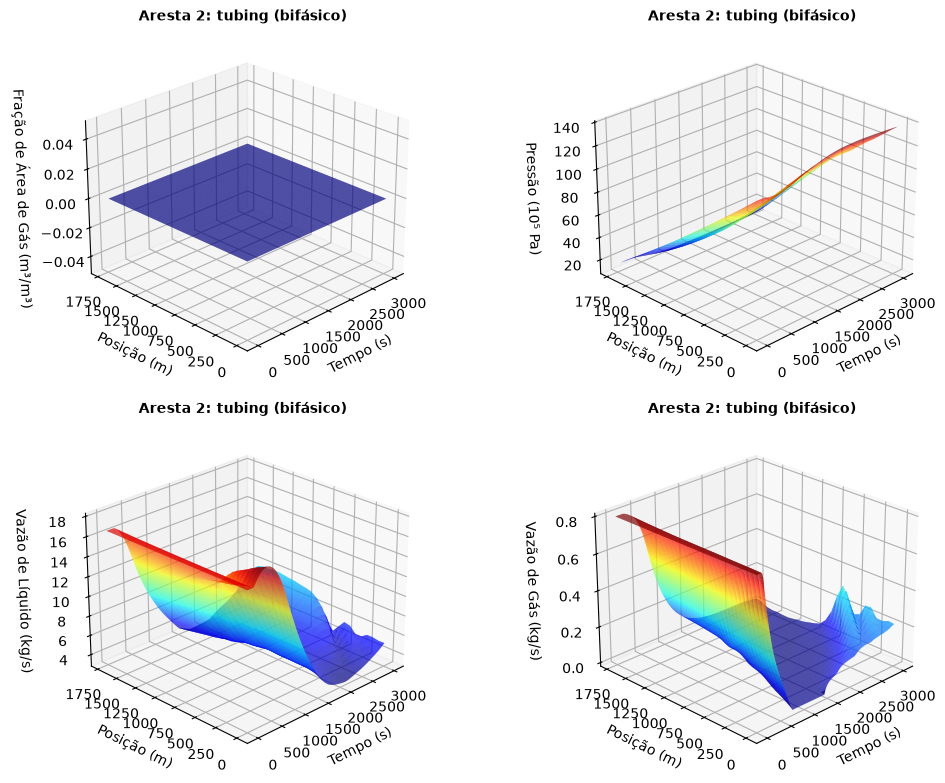

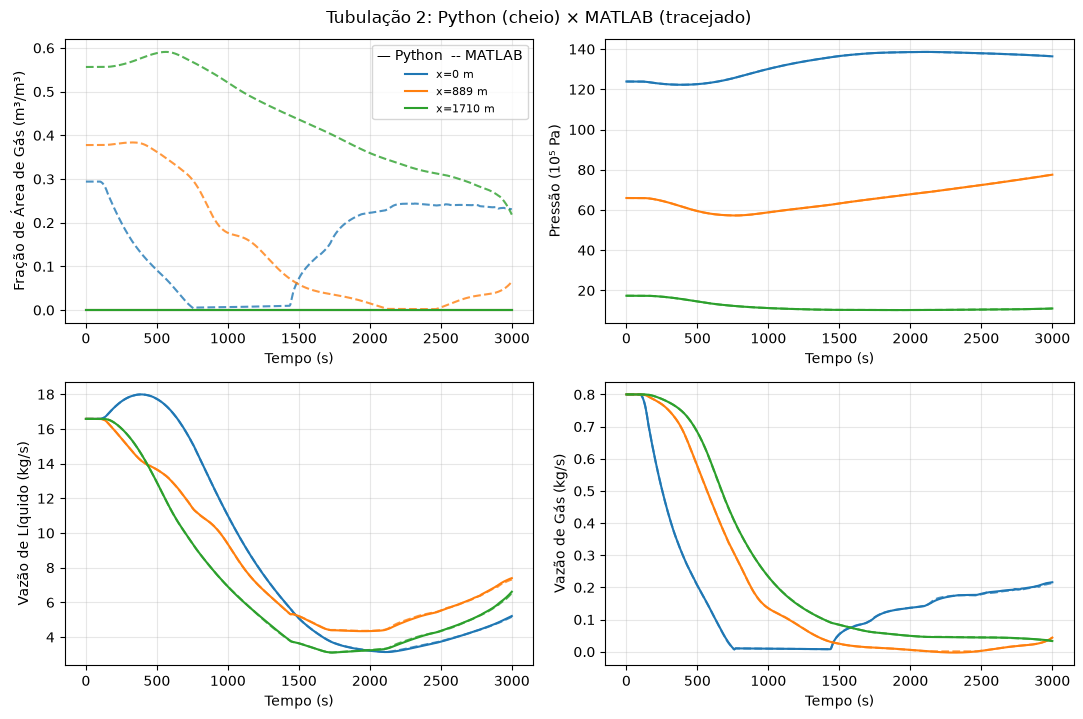

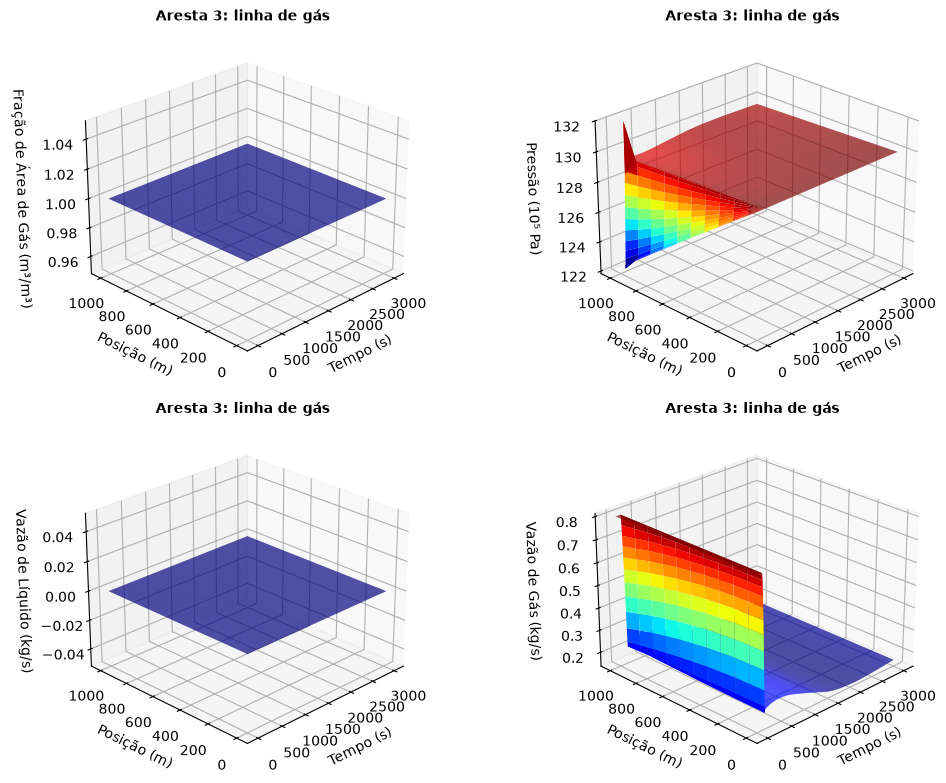

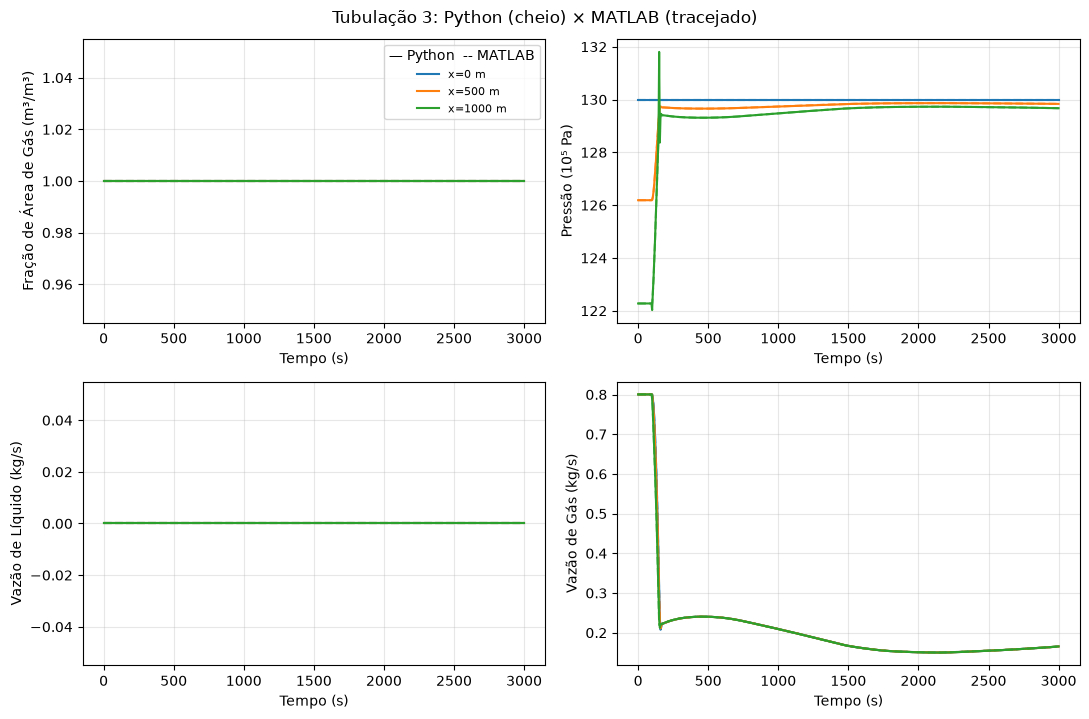

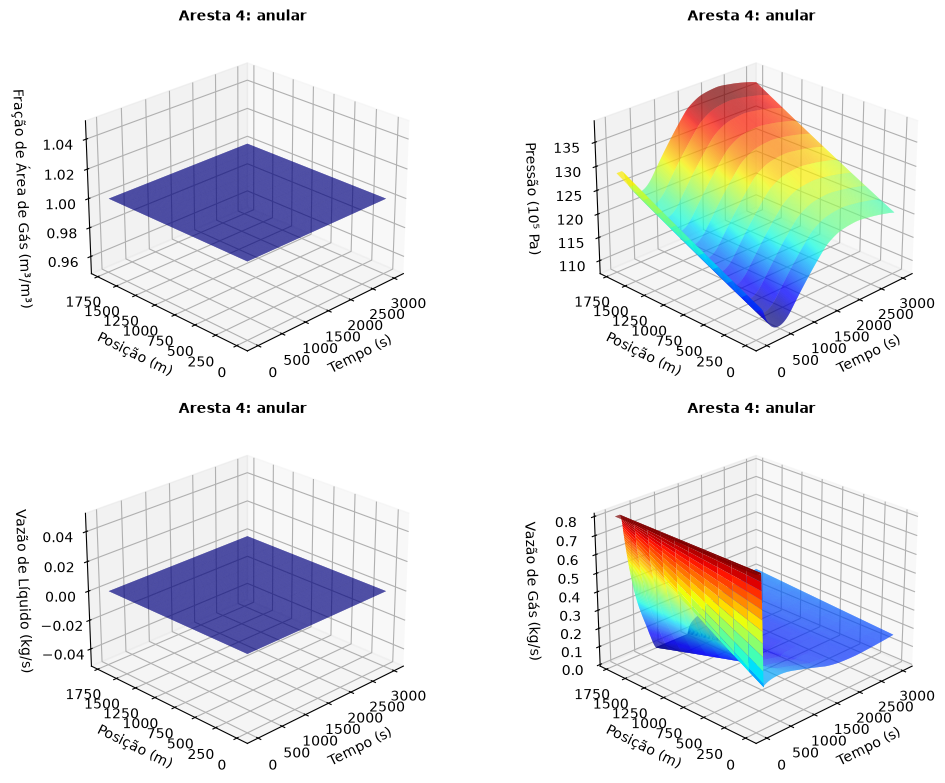

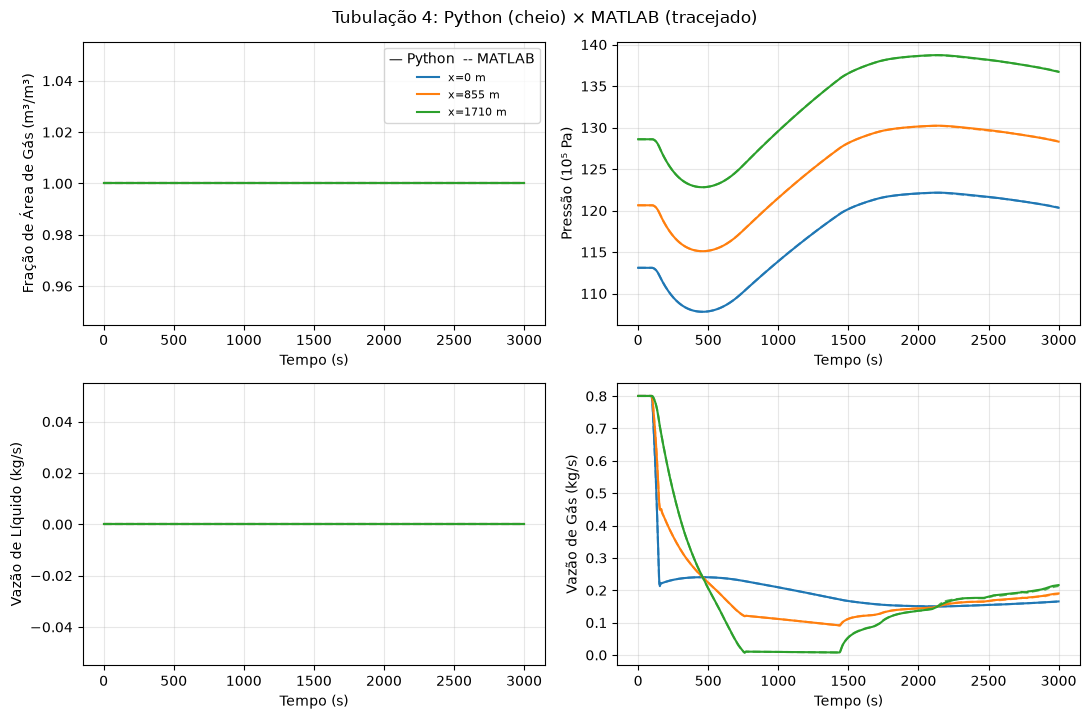

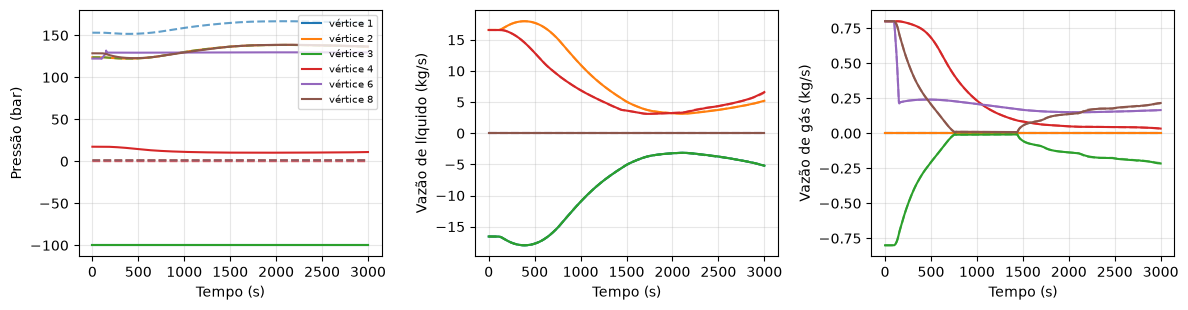

In [2]:
run, res, raw = thesis_run("10.3.2b")
compare_states(res, raw)
plot_elements(res, raw)
for k, nm in enumerate(names):
    show_pipe(res, raw, k, title=f"Aresta {k + 1}: {nm}")
plot_vertices(res, raw, indices=[1, 2, 3, 4, 6, 8])

## Cenário 1 - sem intermitência

10.3.2 Poço com gas lift - cenário 1 (sem intermitência)
Choke de gás 100%->75% entre 100 e 150 s.
Figuras da tese: Figs. 10.36-10.40
corrida 10_3_2a.npz: integrador bdf (rtol 0.0001, atol 0.01, max_step 5.0), 601 instantes de saída até 3000 s


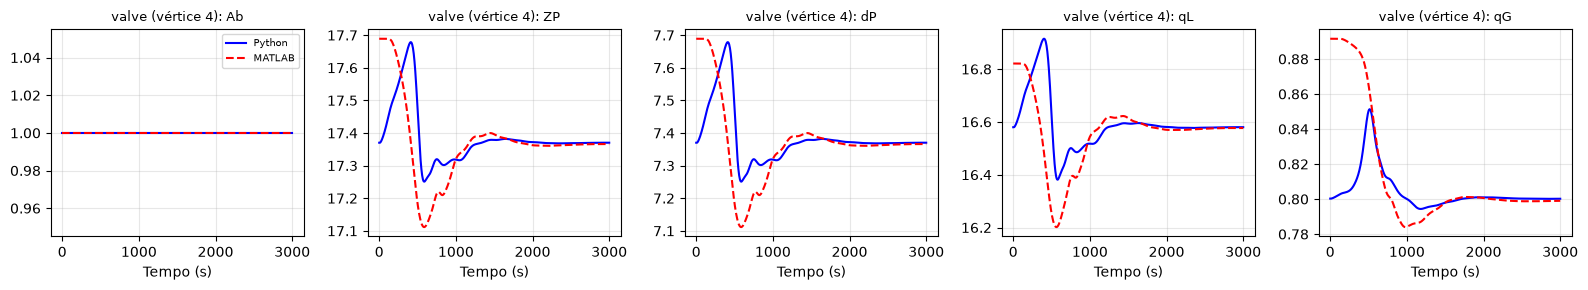

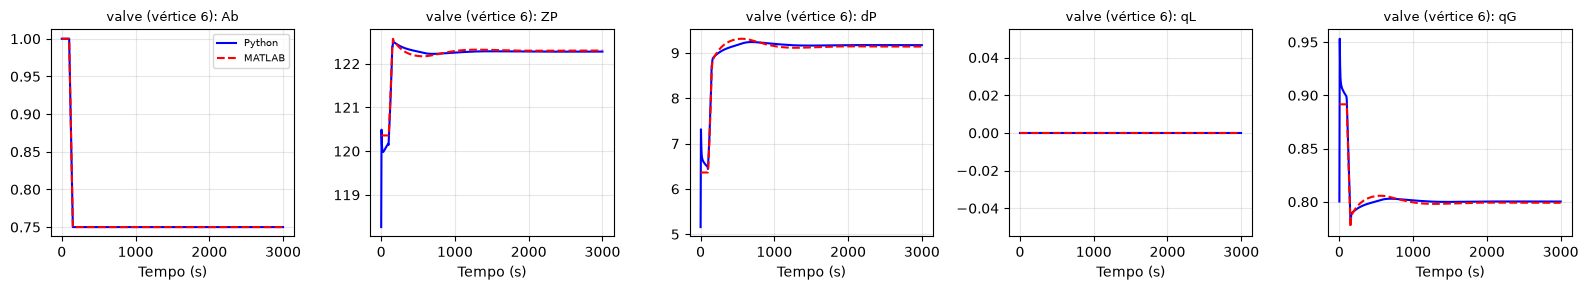

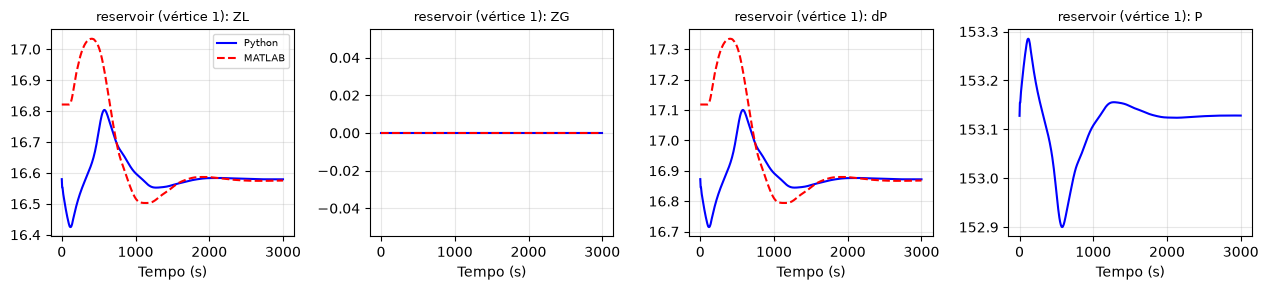

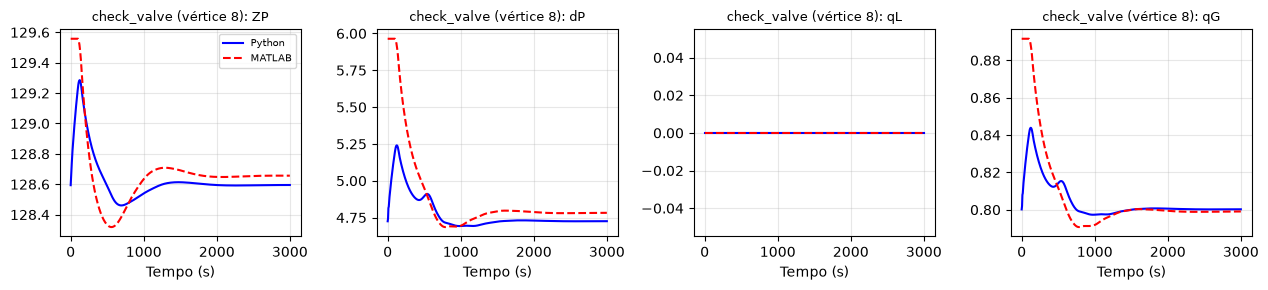

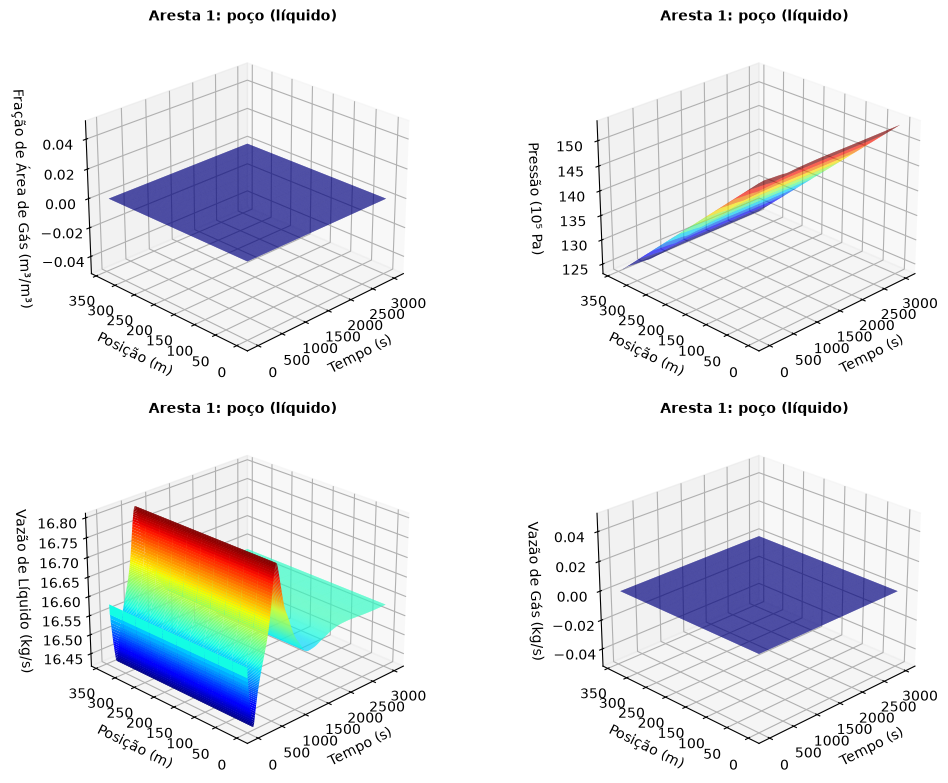

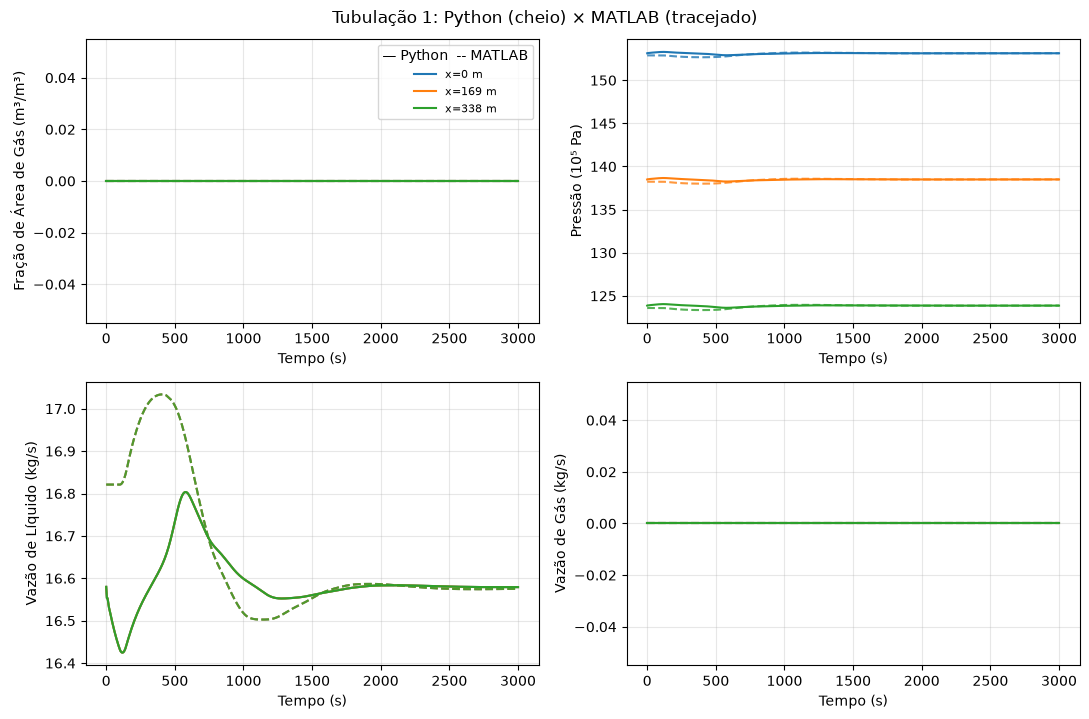

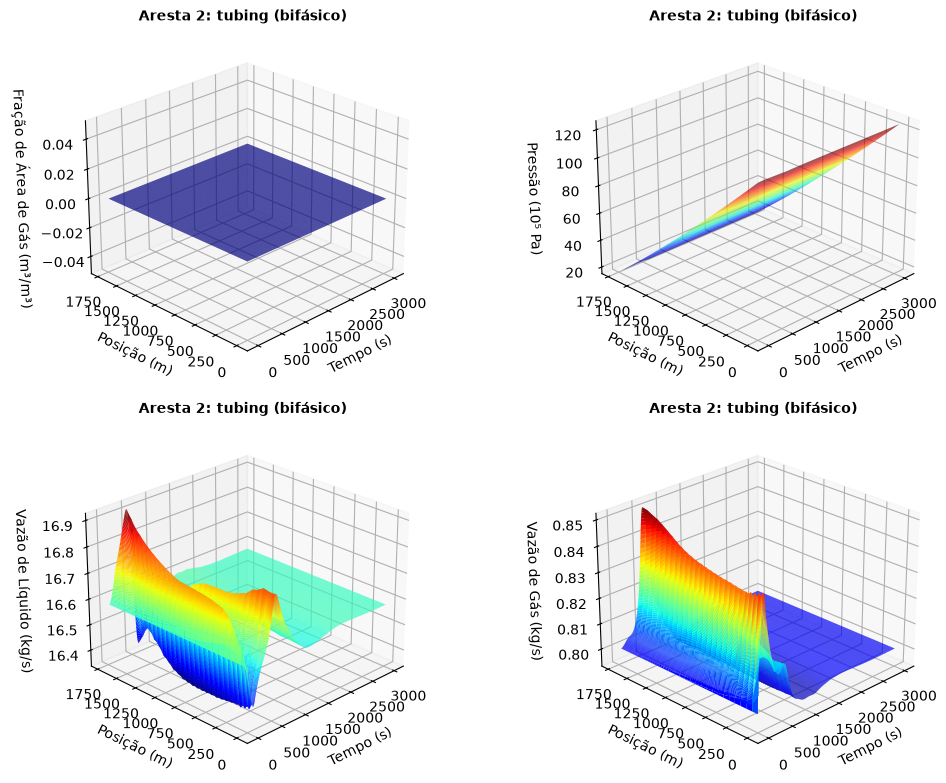

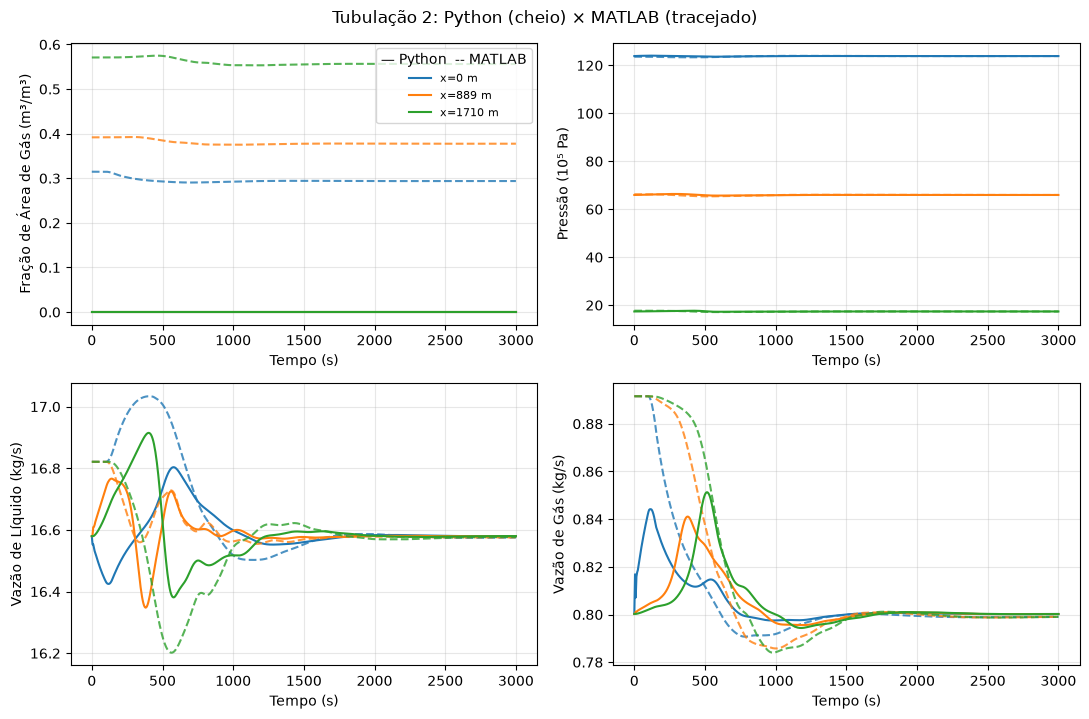

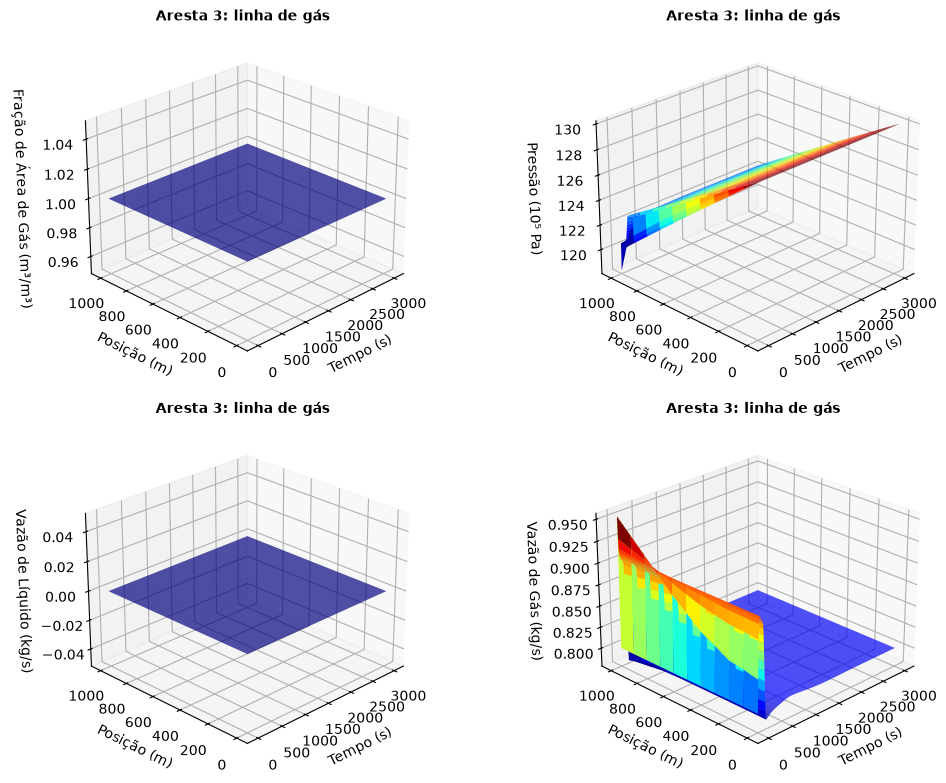

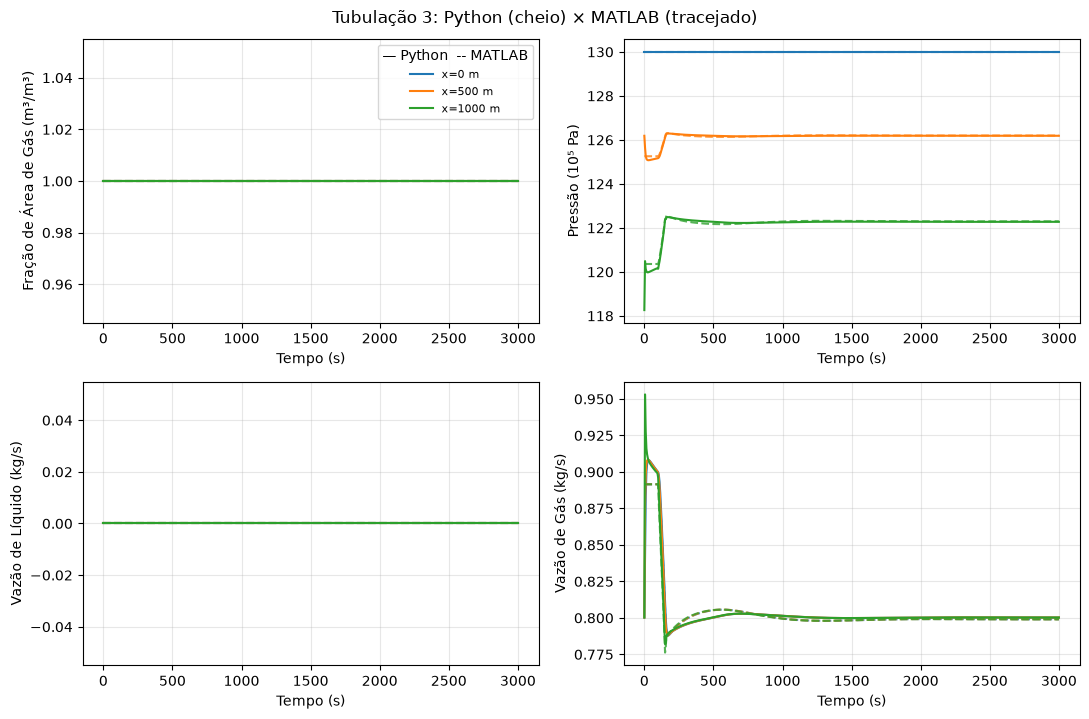

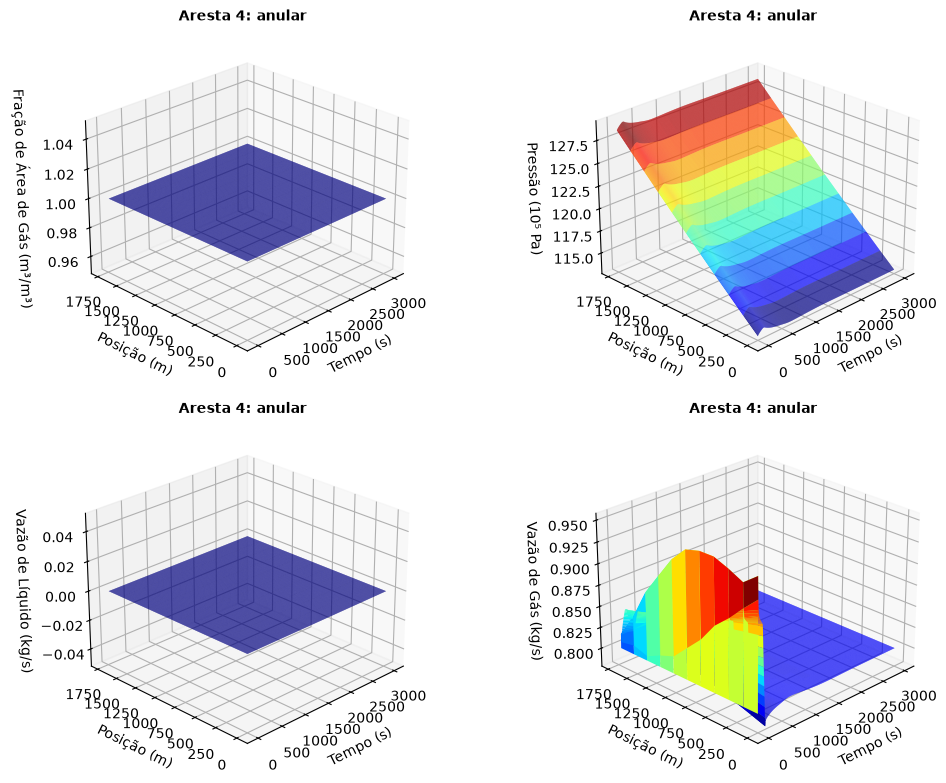

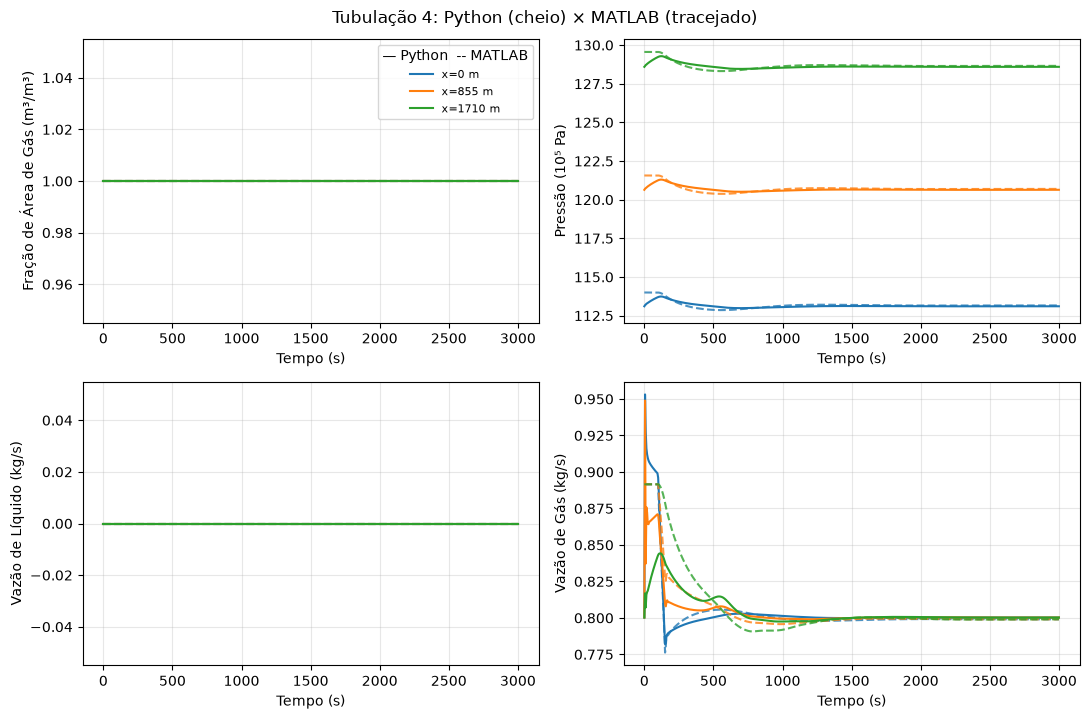

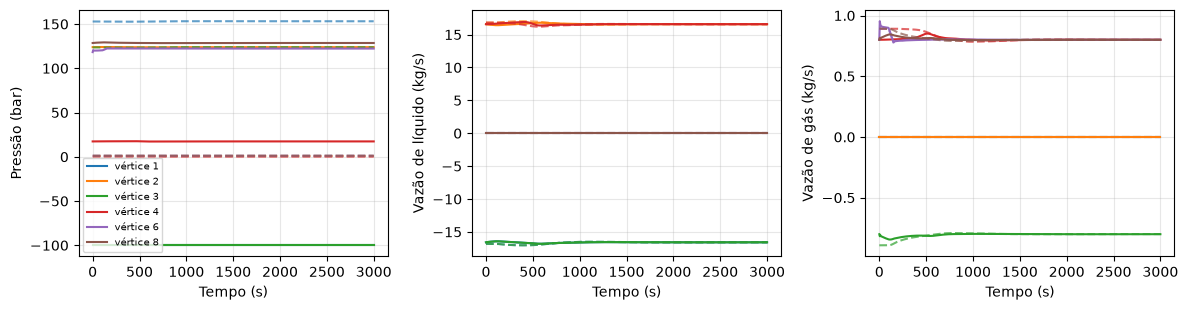

In [3]:
run1, res1, raw1 = thesis_run("10.3.2a")
plot_elements(res1, raw1)
for k, nm in enumerate(names):
    show_pipe(res1, raw1, k, title=f"Aresta {k + 1}: {nm}")
plot_vertices(res1, raw1, indices=[1, 2, 3, 4, 6, 8])

---
*Notebook de reprodução fiel: nenhuma simulação corre aqui. As corridas vêm do lote
`batches/thesis.json` (`uv run mfsim batch batches/thesis.json`), com a configuração exportada
do ficheiro original; as correções e melhorias estão nos notebooks de `notebooks_src/issues/`
e no índice [docs/issues/INDEX.md](../../docs/issues/INDEX.md).*